<a href="https://colab.research.google.com/github/Akash14-09/ML_Projects/blob/main/Cats_VS_Dog_Image_Classification_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

In [2]:
!pip -q install kagglehub

import kagglehub

path = kagglehub.dataset_download("salader/dogsvscats")

print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'dogsvscats' dataset.
Dataset downloaded to: /kaggle/input/dogsvscats


In [3]:
import os

print(os.listdir(path))

['test', 'train', 'catsvsdogs']


In [13]:
for root, dirs, files in os.walk(path):
    print(root, ":", len(files), "files")

/kaggle/input/dogsvscats : 0 files
/kaggle/input/dogsvscats/test : 0 files
/kaggle/input/dogsvscats/test/dogs : 2500 files
/kaggle/input/dogsvscats/test/cats : 2500 files
/kaggle/input/dogsvscats/train : 0 files
/kaggle/input/dogsvscats/train/dogs : 10000 files
/kaggle/input/dogsvscats/train/cats : 10000 files
/kaggle/input/dogsvscats/catsvsdogs : 0 files
/kaggle/input/dogsvscats/catsvsdogs/test : 0 files
/kaggle/input/dogsvscats/catsvsdogs/test/dogs : 2500 files
/kaggle/input/dogsvscats/catsvsdogs/test/cats : 2500 files
/kaggle/input/dogsvscats/catsvsdogs/train : 0 files
/kaggle/input/dogsvscats/catsvsdogs/train/dogs : 10000 files
/kaggle/input/dogsvscats/catsvsdogs/train/cats : 10000 files


In [5]:
import shutil

shutil.copytree(path, "/content/dogsvscats", dirs_exist_ok=True)

'/content/dogsvscats'

In [6]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, BatchNormalization, Dropout



In [7]:
#genrators
train_ds = keras.utils.image_dataset_from_directory(
    directory='/content/dogsvscats/train',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256,256)

)
validation_ds = keras.utils.image_dataset_from_directory(
    directory='/content/dogsvscats/test',
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32,
    image_size = (256,256)

)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [8]:
#normalize
def process(image , label) :
  image = tf.cast(image/255. , tf.float32)
  return image , label
train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [16]:
#now we need to create the cnn model

model = Sequential()
model.add(Conv2D(32, kernel_size=(3,3), padding='valid', activation='relu', input_shape=(256,256,3)))

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))
model.add(Conv2D(64, kernel_size=(3,3), padding='valid', activation='relu'))

model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))
model.add(Conv2D(128, kernel_size=(3,3), padding='valid', activation='relu'))


model.add(BatchNormalization())

model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding='valid'))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [18]:
model.compile(optimizer = 'adam' , loss = 'binary_crossentropy' , metrics = ['accuracy'])

In [19]:
history = model.fit(train_ds , epochs = 10 , validation_data = validation_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 99ms/step - accuracy: 0.5455 - loss: 1.6874 - val_accuracy: 0.5550 - val_loss: 0.6764
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.6220 - loss: 0.6558 - val_accuracy: 0.5950 - val_loss: 0.6486
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.6945 - loss: 0.5892 - val_accuracy: 0.7514 - val_loss: 0.5228
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.7405 - loss: 0.5311 - val_accuracy: 0.6710 - val_loss: 0.5907
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 65s 104ms/step - accuracy: 0.7808 - loss: 0.4769 - val_accuracy: 0.6918 - val_loss: 0.5967
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 65s 104ms/step - accuracy: 0.8080 - loss: 0.4344 - val_accuracy: 0.7914 - val_loss: 0.4408
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.8371 - loss: 0.3740 - val_accuracy: 0.8242 - val_loss: 0.4025
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.8663 - loss: 0.3200 

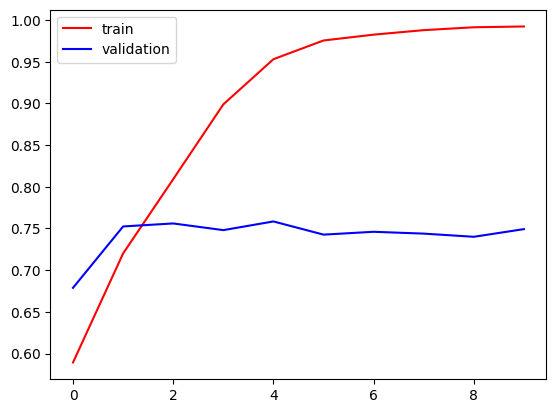

In [14]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'] , color = 'red' , label = 'train')
plt.plot(history.history['val_accuracy' ] , color = 'blue' , label = 'validation')
plt.legend()
plt.show()

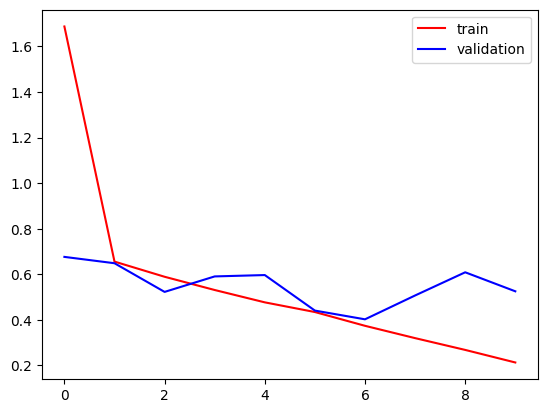

In [20]:
plt.plot(history.history['loss'] , color = 'red' , label = 'train')
plt.plot(history.history['val_loss' ] , color = 'blue' , label = 'validation')
plt.legend()
plt.show()


In [ ]:
#ways to reduce overfitting

"""
1. Add more data
2. Data Augmentation (wont use here bcs havent studied)
3. L1/L2 Regularization
4. Dropout
5. Batch Normalization
6. Reduce Complexity
"""

###Prediction on new image


In [21]:
import cv2

In [35]:
test_img = cv2.imread('/content/cross-breed-dog-1-year-old-sitting-front-white-wall_191971-2931.avif')

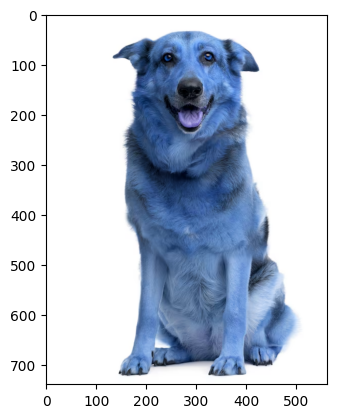

In [36]:
plt.imshow(test_img)

In [37]:
test_img.shape

(740, 563, 3)

In [38]:
test_img = cv2.resize(test_img , (256,256))

In [39]:
test_input = test_img.reshape((1,256,256,3))
#we pass data in batches means in this batch only one image exist whose dimension is this

In [40]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


array([[0.]], dtype=float32)